<a href="https://colab.research.google.com/github/alfiahlutfi/pm-turi4-clustering/blob/main/PM_P9_Alfiah_Lutfi_Sabilah_2488010032.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 — Menyiapkan data & scaling (wajib).

In [18]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)
df = pd.DataFrame({
    'usia': [19, 25, 30, 35, 40, 45, 22, 28, 50, 55],
    'pendapatan': [3000, 4000, 5000, 6000, 7000,
                   8000, 3500, 4500, 9000, 10000],
    'skor_belanja': [80, 75, 60, 50, 40, 30, 85, 70, 25, 20]
})
X_scaled = StandardScaler().fit_transform(df)

Langkah 2 — Metode Elbow menentukan K.

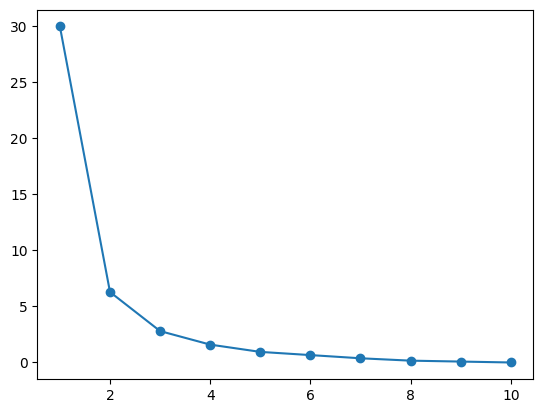

In [19]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


Langkah 3 — Menjalankan K-Means (K=3).

In [20]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
2    4
0    3
1    3
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.

In [21]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.4862843390428829


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [22]:

profil = df.groupby('cluster')[['usia', 'pendapatan',
    'skor_belanja']].mean().round(1)

print("Profil Rata-rata Tiap Cluster:")
print(profil)

print("\nInterpretasi Cluster:")
for cluster, data in profil.iterrows():
    if data['skor_belanja'] >= 60:
        nama = "Pelanggan dengan Skor Belanja Tinggi"
    elif data['skor_belanja'] >= 40:
        nama = "Pelanggan dengan Skor Belanja Sedang"
    else:
        nama = "Pelanggan dengan Skor Belanja Rendah"

    print(f"Cluster {cluster}: {nama}")
    print(f"  Usia rata-rata: {data['usia']} tahun")
    print(f"  Pendapatan rata-rata: {data['pendapatan']}")
    print(f"  Skor belanja rata-rata: {data['skor_belanja']}")


Profil Rata-rata Tiap Cluster:
         usia  pendapatan  skor_belanja
cluster                                
0        35.0      6000.0          50.0
1        50.0      9000.0          25.0
2        23.5      3750.0          77.5

Interpretasi Cluster:
Cluster 0: Pelanggan dengan Skor Belanja Sedang
  Usia rata-rata: 35.0 tahun
  Pendapatan rata-rata: 6000.0
  Skor belanja rata-rata: 50.0
Cluster 1: Pelanggan dengan Skor Belanja Rendah
  Usia rata-rata: 50.0 tahun
  Pendapatan rata-rata: 9000.0
  Skor belanja rata-rata: 25.0
Cluster 2: Pelanggan dengan Skor Belanja Tinggi
  Usia rata-rata: 23.5 tahun
  Pendapatan rata-rata: 3750.0
  Skor belanja rata-rata: 77.5


6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [23]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Silhouette score untuk K=3
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster3 = kmeans3.fit_predict(X_scaled)
silhouette3 = silhouette_score(X_scaled, cluster3)

# Silhouette score untuk K=5
kmeans5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster5 = kmeans5.fit_predict(X_scaled)
silhouette5 = silhouette_score(X_scaled, cluster5)

print("Silhouette Score K=3:", round(silhouette3, 4))
print("Silhouette Score K=5:", round(silhouette5, 4))

if silhouette5 > silhouette3:
    print("Kesimpulan: K=5 menghasilkan cluster yang lebih baik berdasarkan silhouette score.")
elif silhouette5 < silhouette3:
    print("Kesimpulan: K=3 menghasilkan cluster yang lebih baik berdasarkan silhouette score.")
else:
    print("Kesimpulan: K=3 dan K=5 memiliki silhouette score yang sama.")

Silhouette Score K=3: 0.4863
Silhouette Score K=5: 0.3735
Kesimpulan: K=3 menghasilkan cluster yang lebih baik berdasarkan silhouette score.


7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [24]:

# Data asli tanpa scaling
X = df[['usia', 'pendapatan', 'skor_belanja']]

# K-Means K=3 tanpa scaling
kmeans_no_scaling = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_no_scaling = kmeans_no_scaling.fit_predict(X)

# Evaluasi silhouette tanpa scaling
silhouette_no_scaling = silhouette_score(X, cluster_no_scaling)

print("Silhouette Score dengan scaling:", round(silhouette3, 4))
print("Silhouette Score tanpa scaling:", round(silhouette_no_scaling, 4))

if silhouette3 > silhouette_no_scaling:
    print("Kesimpulan: Pada data ini, hasil silhouette dengan scaling lebih baik.")
elif silhouette3 < silhouette_no_scaling:
    print("Kesimpulan: Pada data ini, hasil silhouette tanpa scaling lebih baik.")
else:
    print("Kesimpulan: Kedua metode menghasilkan silhouette score yang sama.")

Silhouette Score dengan scaling: 0.4863
Silhouette Score tanpa scaling: 0.5229
Kesimpulan: Pada data ini, hasil silhouette tanpa scaling lebih baik.


8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

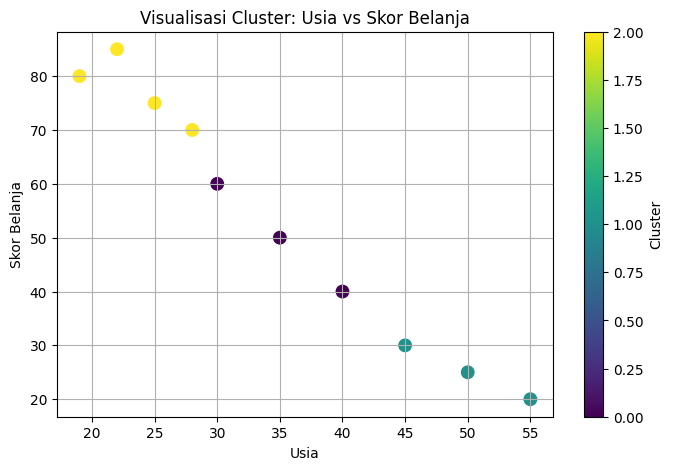

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df['usia'],
    df['skor_belanja'],
    c=cluster3,
    cmap='viridis',
    s=80
)

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Visualisasi Cluster: Usia vs Skor Belanja')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

9. Bagaimana K-Means menemukan kelompok tanpa label?

Jawab:

K-Means mengelompokkan data berdasarkan kemiripan karakteristik tanpa memerlukan label sebelumnya. Data yang memiliki karakteristik mirip akan masuk ke kelompok yang sama, sedangkan data yang berbeda akan masuk ke kelompok lain. Contohnya yaitu segmentasi pelanggan berdasarkan usia, pendapatan, dan skor belanja.

10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Jawab:

Metode Elbow menunjukkan siku di K = 3 karena pada titik tersebut penurunan nilai inertia mulai melambat. Artinya membagi data menjadi 3 cluster sudah cukup baik untuk mengelompokkan data, sedangkan menambah jumlah cluster hanya memberikan sedikit peningkatan hasil pengelompokan.

11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Jawab

Scaling penting untuk menyamakan skala nilai setiap fitur agar tidak ada fitur yang mendominasi perhitungan jarak. Jika scaling dilewatkan, fitur dengan nilai besar seperti pendapatan dapat lebih memengaruhi hasil pengelompokan dibandingkan fitur lain yang akan mengakibatkan hasil cluster bisa kurang optimal dan tidak mewakili kemiripan data secara seimbang.